# MDPToolbox vs Marmote vs MDPSolver

Les 51 modèles du catalogue, avec leurs paramètres par défaut, et les 17 solveurs
de ces trois bibliothèques sont ajoutés explicitement, un par un.

Utiliser un noyau Python 3.11+ avec les dépendances installées depuis la racine :
```sh
python -m pip install -e ".[notebooks,mdptoolbox,marmote,mdpsolver,maze]"
```

Le benchmark vérifie la précision absolue par le résidu complet de Bellman.
Le timeout s'applique à chaque essai de solveur ; les modèles réutilisent leur
cache lorsqu'il existe. Utiliser MDPSolver 0.10.2 ou plus récent pour le correctif
VI/SOR ; les exports historiques en 0.10.1 peuvent contenir les anciennes erreurs.

In [1]:
import random

import numpy as np

from mdpforge import Benchmark

DISCOUNT = 0.9
SIZE = "small"
PRECISION = 1e-3
REPEATS = 1
SEED = 0
TIMEOUT = 2  # Secondes par essai ; None désactive l'isolation en processus.

np.random.seed(SEED)
random.seed(SEED)

In [2]:
bench = Benchmark(default_solvers=False)
bench.reset()
bench.add_solver("mdptoolbox_mpi")
bench.add_solver('mdptoolbox_vi')
bench.add_all_mdps(size=SIZE, verbose=True)

Loading/building model 'access_control'...
Added MDP '500_2_access_control' (500 states, 2 actions) in 0.011 s
Loading/building model 'acrobot'...
Added MDP '2402_3_acrobot' (2402 states, 3 actions) in 0.004 s
Loading/building model 'admission'...
Added MDP '1008_2_admission' (1008 states, 2 actions) in 0.081 s
Loading/building model 'ambulance'...
Added MDP '500_10_ambulance' (500 states, 10 actions) in 0.636 s
Loading/building model 'ambulance_relocation'...
Added MDP '1000_10_ambulance_relocation' (1000 states, 10 actions) in 0.021 s
Loading/building model 'barto'...
Added MDP '726_9_barto_3_0.1' (726 states, 9 actions) in 0.336 s
Loading/building model 'block'...
Added MDP '250_10_block_0.85_10' (250 states, 10 actions) in 0.400 s
Loading/building model 'blocks_world'...
Added MDP '5000_6_blocks_world' (5000 states, 6 actions) in 0.005 s
Loading/building model 'boxworld'...
Added MDP '514_5_boxworld_v1_n16_delay0.2_damage0.025' (514 states, 5 actions) in 0.007 s
Loading/building mo

In [3]:
results = bench.run(
    discount=DISCOUNT,
    precision=PRECISION,
    repeats=REPEATS,
    seed=SEED,
    timeout=5,
    verbose=True,
)

500_2_access_control / mdptoolbox_mpi [1/1]: success (0.016 s)
500_2_access_control / mdptoolbox_vi [1/1]: success (0.002 s)
2402_3_acrobot / mdptoolbox_mpi [1/1]: success (0.568 s)
2402_3_acrobot / mdptoolbox_vi [1/1]: success (0.006 s)
1008_2_admission / mdptoolbox_mpi [1/1]: success (0.105 s)
1008_2_admission / mdptoolbox_vi [1/1]: success (0.005 s)
500_10_ambulance / mdptoolbox_mpi [1/1]: success (0.080 s)
500_10_ambulance / mdptoolbox_vi [1/1]: success (0.010 s)
1000_10_ambulance_relocation / mdptoolbox_mpi [1/1]: success (0.305 s)
1000_10_ambulance_relocation / mdptoolbox_vi [1/1]: success (0.043 s)
726_9_barto_3_0.1 / mdptoolbox_mpi [1/1]: success (0.102 s)
726_9_barto_3_0.1 / mdptoolbox_vi [1/1]: success (0.002 s)
250_10_block_0.85_10 / mdptoolbox_mpi [1/1]: success (0.023 s)
250_10_block_0.85_10 / mdptoolbox_vi [1/1]: success (0.009 s)
5000_6_blocks_world / mdptoolbox_mpi [1/1]: timeout (nan s) — Trial exceeded timeout of 5 s
5000_6_blocks_world / mdptoolbox_vi [1/1]: success 

C:\Users\orsof\github\mdpforge\src\mdpforge\utils\plotting.py:151: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  fig.tight_layout()


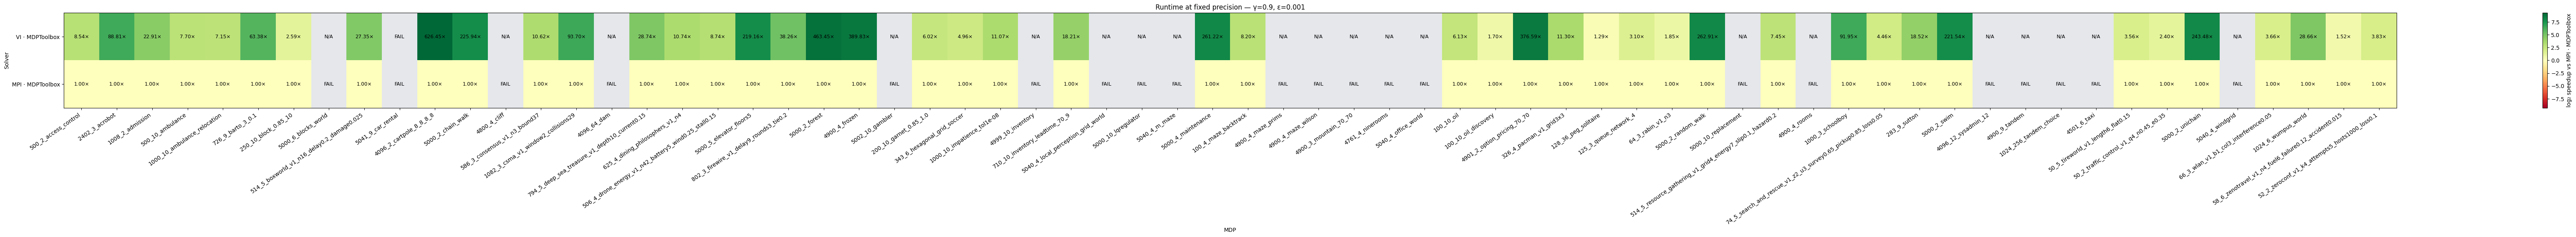

(<Figure size 9440x310 with 2 Axes>,
 <Axes: title={'center': 'Runtime at fixed precision — γ=0.9, ε=0.001'}, xlabel='MDP', ylabel='Solver'>)

In [4]:
results.plot_heat()

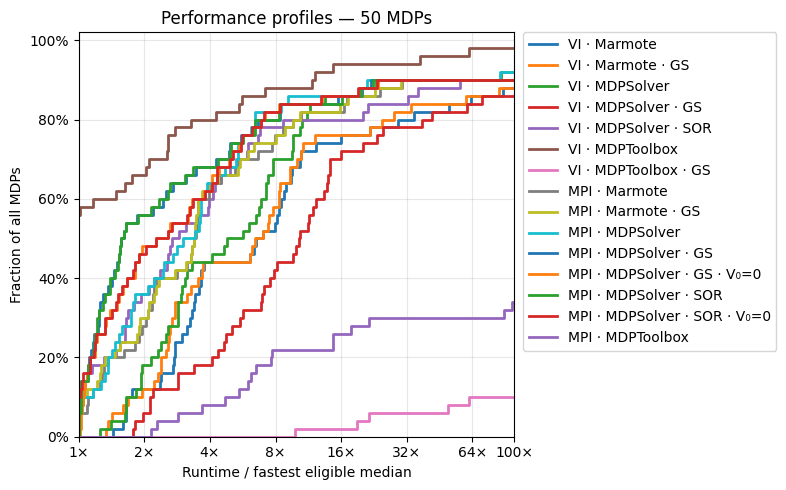

TypeError: imsave() missing 1 required positional argument: 'arr'

In [14]:
results.plot_performance_profile()
import matplotlib.pyplot as plt

plt.imsave("artifacts/figures/benchmark_marmote.pdf")

In [12]:
results.summary()

,model,solver,n_success,n_trials,median_runtime,complete
0,500_2_access_control,marmote_mpi,3,3,0.309664,True
1,500_2_access_control,marmote_mpigs,3,3,0.272224,True
2,500_2_access_control,marmote_vi,3,3,0.424684,True
3,500_2_access_control,marmote_vigs,3,3,0.333245,True
4,500_2_access_control,mdpsolver_mpi,3,3,0.173742,True
...,...,...,...,...,...,...
745,1024_6_wumpus_world,mdpsolver_vigs,3,3,0.063925,True
746,1024_6_wumpus_world,mdpsolver_visor,3,3,0.005891,True
747,1024_6_wumpus_world,mdptoolbox_mpi,3,3,0.785877,True
748,1024_6_wumpus_world,mdptoolbox_vi,3,3,0.081740,True


In [11]:
results.from_csv()

BenchmarkResult(rows=[{'experiment_id': '27645f59-2b91-4ed3-9bc3-fc01a7973376', 'model': '500_2_access_control', 'state_dim': 500, 'requested_state_dim': 500, 'action_dim': 2, 'solver': 'marmote_mpi', 'repeat': 1, 'seed': 0, 'discount': 0.99, 'epsilon': 0.001, 'runtime': 0.3161956999974791, 'residual': 4.900874955637846e-06, 'error_bound': 0.0004900874955637842, 'status': 'success', 'error': ''}, {'experiment_id': '27645f59-2b91-4ed3-9bc3-fc01a7973376', 'model': '500_2_access_control', 'state_dim': 500, 'requested_state_dim': 500, 'action_dim': 2, 'solver': 'marmote_mpi', 'repeat': 2, 'seed': 1, 'discount': 0.99, 'epsilon': 0.001, 'runtime': 0.30294429999776185, 'residual': 4.900874955637846e-06, 'error_bound': 0.0004900874955637842, 'status': 'success', 'error': ''}, {'experiment_id': '27645f59-2b91-4ed3-9bc3-fc01a7973376', 'model': '500_2_access_control', 'state_dim': 500, 'requested_state_dim': 500, 'action_dim': 2, 'solver': 'marmote_mpi', 'repeat': 3, 'seed': 2, 'discount': 0.99, 